In [34]:
!kaggle --version

Kaggle CLI 2.2.3


In [2]:
!pip install --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.5/111.5 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.8/243.8 kB 26.5 MB/s eta 0:00:00
  Attempting uninstall: kagglesdk
    Found existing installation: kagglesdk 0.1.23
    Uninstalling kagglesdk-0.1.23:
      Successfully uninstalled kagglesdk-0.1.23
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [3]:
!kaggle --version

Kaggle CLI 2.2.3


In [4]:
!kaggle datasets download -d MasoudNickparvar/Brain-Tumor-MRI-Dataset


Dataset URL: https://www.kaggle.com/datasets/MasoudNickparvar/Brain-Tumor-MRI-Dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:07<00:00, 20.9MB/s]



In [5]:
import zipfile
import os

zip_ref = zipfile.ZipFile('/content/Brain-Tumor-MRI-Dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [8]:
import os
import numpy as np
import random
from PIL import Image
import PIL.ImageEnhance
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Flatten,Dropout,Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle

In [12]:
train_dir = '/content/Training'
test_dir = '/content/Testing'
#load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
  for image in os.listdir(os.path.join(train_dir,label)):
    train_paths.append(os.path.join(train_dir,label,image))
    train_labels.append(label)
train_paths,train_labels = shuffle(train_paths,train_labels)

test_paths = []
test_labels = []
for label in os.listdir(test_dir):
  for image in os.listdir(os.path.join(test_dir,label)):
    test_paths.append(os.path.join(test_dir,label,image))
    test_labels.append(label)
test_paths,test_labels = shuffle(test_paths,test_labels)



**Data visualization**

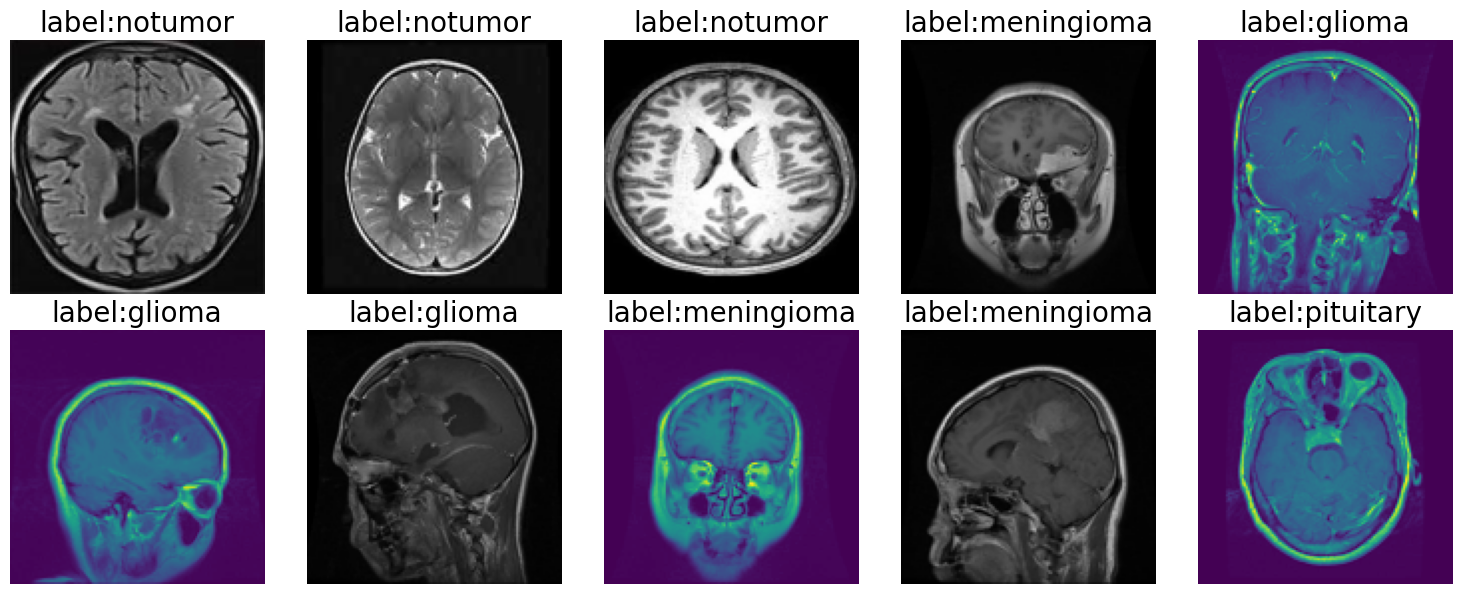

In [20]:
import random
import matplotlib.pyplot as plt
#select random indices for 10 images
random_indices = random.sample(range(len(train_paths)),10)
#create a figure to display images in 2 rows
fig,axes = plt.subplots(2,5,figsize=(15,6))
axes = axes.ravel()
#loop through the random indices and display images
for i,idx in enumerate(random_indices):
  img_path = train_paths[idx]
  img = Image.open(img_path)
  img = img.resize((128,128))
  #display images
  axes[i].imshow(img)
  axes[i].axis("off")
  axes[i].set_title(f"label:{train_labels[idx]}",fontsize=20)
plt.tight_layout()
plt.show()


**Image Preprocessing**

In [27]:
#Image Augmentation Function
def augment_image(image):
  image = Image.fromarray(np.uint8(image))
  image = PIL.ImageEnhance.Brightness(image).enhance(random.uniform(0.8,1.2))
  image = PIL.ImageEnhance.Contrast(image).enhance(random.uniform(0.8,1.2))
  image = np.array(image)/255.0
  return image
#load images and apply augmentation
def open_images(paths):
  images = []
  for path in paths:
    img = load_img(path,target_size=(IMAGE_SIZE,IMAGE_SIZE))
    img = augment_image(img)
    images.append(img)
  return np.array(images)


#encoder labels (convert label names to integers)
def encode_label(labels):
  unique_labels = os.listdir(train_dir)
  encoded = [unique_labels.index(label) for label in unique_labels]
  return encoded

#Data generator for batching
def datagen(paths,labels,batch_size = 12,epochs = 1):
  for _ in range(epochs):
    for i in range(0,len(paths),batch_size):
      batch_paths = paths[i:i+batch_size]
      batch_images = open_images(batch_paths)
      batch_labels = labels[i:i+batch_size]
      batch_labels = encode_label(batch_labels)
      yield batch_images,batch_labels



In [28]:
#image architecture
IMAGE_SIZE = 128
base_model = VGG16(input_shape=(IMAGE_SIZE,IMAGE_SIZE,3),include_top=False,weights="imagenet")

#freeze all layers of the VGG16 base model
for layer in base_model.layers:
  layer.trainable = False
#set only the last few layers
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True
#Build model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE,IMAGE_SIZE,3)))
model.add(base_model)
model.add(Flatten())
model.add(Dropout(0.3))
model.add(Dense(128,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(len(os.listdir(train_dir)),activation='softmax'))

#compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),loss='sparse_categorical_crossentropy',metrics=['sparse_categorical_accuracy'])
#parameters
batch_size = 20
steps = int(len(train_paths)/batch_size)
epochs = 5
#train the model
history = model.fit(datagen(train_paths,train_labels,batch_size = batch_size,epochs=epochs),epochs=epochs,steps_per_epoch=steps)

ValueError: When passing a dataset to a Keras model, the arrays must be at least rank 1. Received: 0 of rank 0.

In [32]:
# Image Augmentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = PIL.ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))  # Random brightness
    image = PIL.ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))  # Random contrast
    image = np.array(image) / 255.0  # Normalize pixel values to [0, 1]
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = augment_image(image)
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
def encode_label(labels):
    unique_labels = os.listdir(train_dir)  # Ensure unique labels are determined
    encoded = [unique_labels.index(label) for label in labels]
    return np.array(encoded)

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch

In [33]:
# Model architecture
IMAGE_SIZE = 128  # Image size (adjust based on your requirements)
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

# Freeze all layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set the last few layers of the VGG16 base model to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))  # Input layer
model.add(base_model)  # Add VGG16 base model
model.add(Flatten())  # Flatten the output of the base model
model.add(Dropout(0.3))  # Dropout layer for regularization
model.add(Dense(128, activation='relu'))  # Dense layer with ReLU activation
model.add(Dropout(0.2))  # Dropout layer for regularization
model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))  # Output layer with softmax activation

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

# Parameters
batch_size = 20
steps = int(len(train_paths) / batch_size)  # Steps per epoch
epochs = 5

# Train the model
history = model.fit(datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
                    epochs=epochs, steps_per_epoch=steps)

Epoch 1/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 29s 64ms/step - loss: 0.4687 - sparse_categorical_accuracy: 0.8200
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step - loss: 0.2307 - sparse_categorical_accuracy: 0.9121
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 18s 63ms/step - loss: 0.1627 - sparse_categorical_accuracy: 0.9373
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 18s 63ms/step - loss: 0.1277 - sparse_categorical_accuracy: 0.9521
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step - loss: 0.0863 - sparse_categorical_accuracy: 0.9702


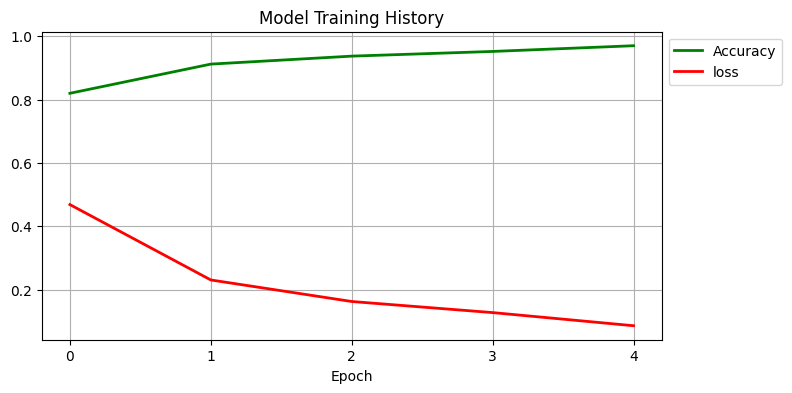

In [35]:
plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'],'g-',linewidth=2)
plt.plot(history.history['loss'],'r-',linewidth=2)
plt.title('Model Training History')
plt.xlabel('Epoch')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy','loss'],loc='upper left',bbox_to_anchor=(1,1))
plt.show()

In [36]:
from sklearn.metrics import confusion_matrix,classification_report,roc_curve,auc
import seaborn as sns
from sklearn.preprocessing import label_binarize

test_images = open_images(test_paths)
test_labels_encoded = encode_label(test_labels)

test_predictions = model.predict(test_images)
print("Classification Report:")
print(classification_report(test_labels_encoded,np.argmax(test_predictions,axis=1)))


50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       400
           1       0.97      0.68      0.80       400
           2       0.78      0.96      0.86       400
           3       0.94      0.99      0.96       400

    accuracy                           0.90      1600
   macro avg       0.91      0.90      0.90      1600
weighted avg       0.91      0.90      0.90      1600



Confusion matrix:
[[389   2   9   0]
 [  9 272  94  25]
 [  6   7 385   2]
 [  0   0   3 397]]


Text(70.72222222222221, 0.5, 'True')

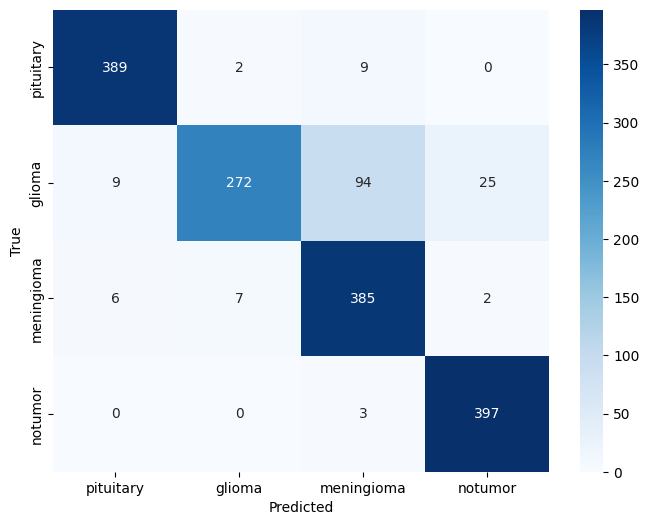

In [37]:
conf_matrix = confusion_matrix(test_labels_encoded,np.argmax(test_predictions,axis=1))
print("Confusion matrix:")
print(conf_matrix)

plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix,annot=True,fmt='d',cmap='Blues',xticklabels=os.listdir(train_dir),yticklabels=os.listdir(train_dir))
plt.xlabel('Predicted')
plt.ylabel('True')

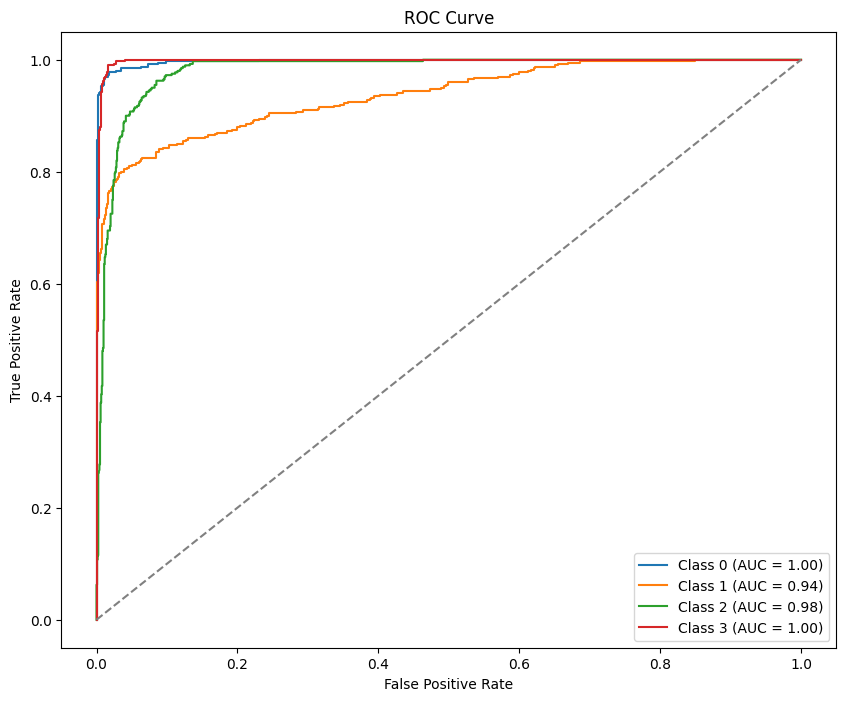

In [38]:
# 4. ROC Curve and AUC
# Binarize the test labels and predictions for multi-class ROC
test_labels_bin = label_binarize(test_labels_encoded, classes=np.arange(len(os.listdir(train_dir))))
test_predictions_bin = test_predictions  # The predicted probabilities for each class

# Compute ROC curve and ROC AUC for each class
fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(os.listdir(train_dir))):
    fpr[i], tpr[i], _ = roc_curve(test_labels_bin[:, i], test_predictions_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve
plt.figure(figsize=(10, 8))
for i in range(len(os.listdir(train_dir))):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal line
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()


**save model**

In [39]:
model.save('model.h5')

In [40]:
from tensorflow.keras.models import load_model
model = load_model('model.h5')

In [41]:
from keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Class labels
class_labels = ['pituitary', 'glioma', 'notumor', 'meningioma']

def detect_and_display(img_path, model, image_size=128):
    """
    Function to detect tumor and display results.
    If no tumor is detected, it displays "No Tumor".
    Otherwise, it shows the predicted tumor class and confidence.
    """
    try:
        # Load and preprocess the image
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = img_to_array(img) / 255.0  # Normalize pixel values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Make a prediction
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]

        # Determine the class
        if class_labels[predicted_class_index] == 'notumor':
            result = "No Tumor"
        else:
            result = f"Tumor: {class_labels[predicted_class_index]}"

        # Display the image with the prediction
        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        plt.show()

    except Exception as e:
        print("Error processing the image:", str(e))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


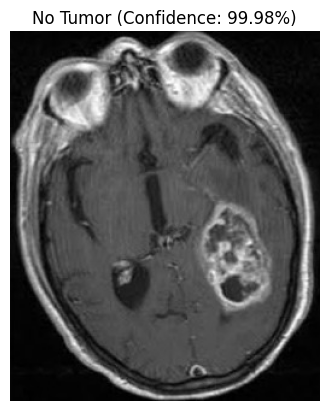

In [47]:
# Example usage
image_path = '/content/Te-meTr_0001.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


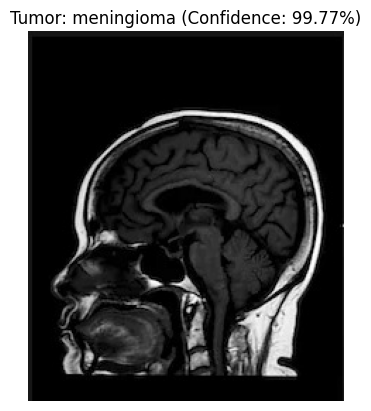

In [49]:
# Example usage
image_path = '/content/Te-noTr_0004.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


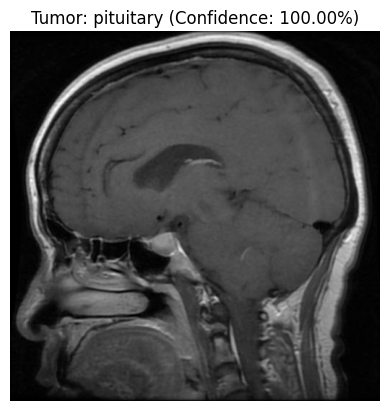

In [45]:
# Example usage
image_path = '/content/Te-piTr_0003.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


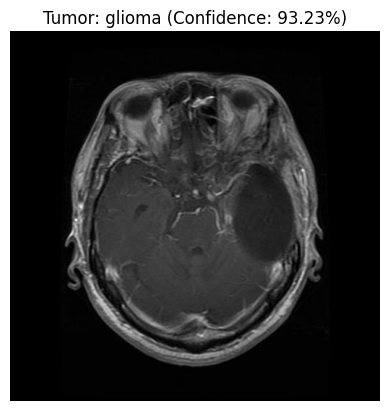

In [46]:
# Example usage
image_path = '/content/Te-gl_0015.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)